# OLIST E-commerce late delivery prediction
## Business Insights and Recommendations

### Objective
Identify the key factors associated with late deliveries and provide actionable recommendations to improve delivery performance

## 1. Key factors influencing late deliveries
The following chart shows the top 15 features identified by our tuned XGBOOST model.

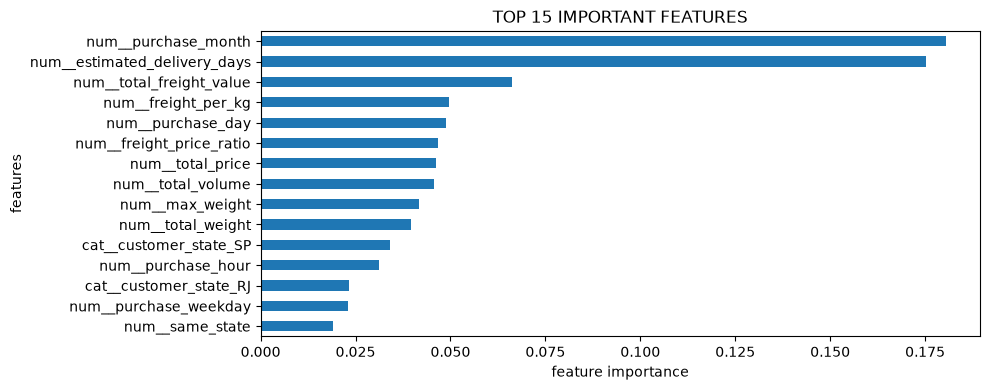

### Initial observations
The XGBOOST model identifies the following as the mostinfluential features:
1. Purchase month
2. Estimated delivery days
3. Total freight value
4. Freight cost per kg
5. Purchase day

These features suggest that delivery delays may be associated with purchase timings, estimated delivery windows, and shipping related factors.

Feature importance indicates predictive contribution, not necessarily causation.

## 2. Business Analysis and Data Preparation
### Objective
In this section, we will analyse the factors influencing late deliveries using the original master late delivery dataset.

The analysis will focus on identifying delivery patterns, understanding key risk factors and translating findings into actionable business recommendations.

We will us ethe dataset to investigate relationships between order characteristics and late delivery outcomes.

### 2.1. Loading the master late delivery dataset

In [2]:
import pandas as pd
import numpy as np
m_df = pd.read_csv(r'C:\Users\acces\OneDrive\Desktop\ML PROJECT\master_late_delivery.csv')

In [3]:
m_df.head()

,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,is_late,customer_city,customer_state,total_items,total_price,total_freight_value,...,avg_length,avg_width,total_payments,total_value,max_installments,total_sellers,seller_state_count,same_state_seller_count,seller_state,multiple_seller_state
0,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35.0000000,2018-08-20 00:00:00.0000000,0,atibaia,SP,1,12.99,12.79,...,16.0,15.0,1.0,25.78,2.0,1,1,1,SP,0
1,00048cc3ae777c65dbb7d2a0634bc1ea,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34.0000000,2017-06-06 00:00:00.0000000,0,uberaba,MG,1,21.90,12.69,...,24.0,15.0,1.0,34.59,1.0,1,1,0,SP,0
2,000e906b789b55f64edcb1f84030f90d,6a3b2fc9f270df258605e22bef19fd88,2017-11-21 18:54:23.0000000,2017-12-07 00:00:00.0000000,1,santa cruz do rio pardo,SP,1,21.99,11.85,...,17.0,12.0,1.0,33.84,3.0,1,1,1,SP,0
3,00130c0eee84a3d909e75bc08c5c3ca1,47d656c08a282ec5ab4c1f18303a3a30,2018-06-11 21:17:00.0000000,2018-06-20 00:00:00.0000000,0,sao bernardo do campo,SP,1,27.90,7.94,...,17.0,13.0,1.0,35.84,1.0,1,1,1,SP,0
4,0020a222f55eb79a372d0efee3cca688,0c45155afd8ff99622c40824057f9b34,2017-08-15 02:45:18.0000000,2017-09-06 00:00:00.0000000,0,volta redonda,RJ,1,29.99,15.10,...,26.0,22.0,1.0,45.09,4.0,1,1,0,SP,0


In [4]:
m_df.shape

(96470, 32)

In [5]:
m_df['is_late'].value_counts()

is_late
0    88644
1     7826
Name: count, dtype: int64

In [13]:
m_df.columns.tolist()

['order_id',
 'customer_id',
 'order_purchase_timestamp',
 'order_estimated_delivery_date',
 'is_late',
 'customer_city',
 'customer_state',
 'total_items',
 'total_price',
 'total_freight_value',
 'avg_price',
 'product_rows',
 'total_weight',
 'total_height',
 'total_length',
 'total_width',
 'max_heigth',
 'max_weight',
 'max_length',
 'max_width',
 'avg_weight',
 'avg_heigth',
 'avg_length',
 'avg_width',
 'total_payments',
 'total_value',
 'max_installments',
 'total_sellers',
 'seller_state_count',
 'same_state_seller_count',
 'seller_state',
 'multiple_seller_state',
 'purchase_month']

### 2.2. Monthly late delivery analysis
Analyze the relationship between purchase month and late delivery rates to identify potential seasonal delivery patterns

In [12]:
m_df['order_purchase_timestamp'] = pd.to_datetime(m_df['order_purchase_timestamp'])
m_df['purchase_month'] = m_df['order_purchase_timestamp'].dt.month

In [43]:
monthly_delivery = m_df.groupby('purchase_month')['is_late'].agg(
    total_orders='count',
    late_orders='sum',
    late_rate='mean',
    late_percent=lambda x:x.mean()*100
)


In [44]:
print(monthly_delivery)

                total_orders  late_orders  late_rate  late_percent
purchase_month                                                    
1                       7819          487   0.062284      6.228418
2                       8208         1101   0.134137     13.413743
3                       9549         1638   0.171536     17.153629
4                       9101          542   0.059554      5.955390
5                      10294          684   0.066446      6.644647
6                       9231          204   0.022099      2.209945
7                      10028          409   0.040786      4.078580
8                      10544          799   0.075778      7.577769
9                       4151          217   0.052277      5.227656
10                      4743          240   0.050601      5.060089
11                      7288         1043   0.143112     14.311196
12                      5514          462   0.083787      8.378672


In [25]:
import matplotlib.pyplot as plt

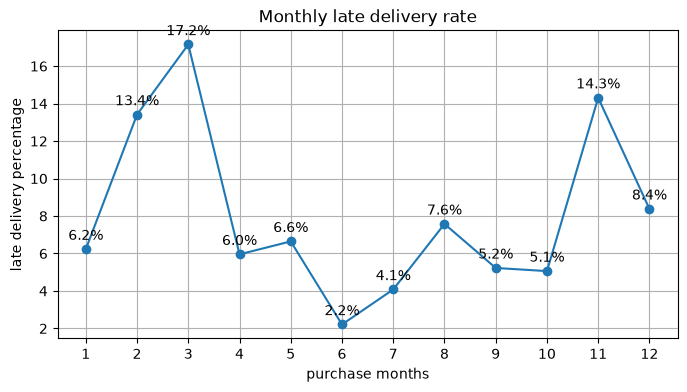

In [54]:
plt.figure(figsize=(8,4))
plt.plot(monthly_delivery.index,monthly_delivery['late_percent'],marker='o')
plt.title('Monthly late delivery rate')
plt.xlabel('purchase months')
plt.ylabel('late delivery percentage')
plt.xticks(range(1,13))
plt.grid(True)
for x, y in zip(monthly_delivery.index,monthly_delivery['late_percent']):
    plt.text(x,y+0.5, f'{y:.1f}%', ha='center')
plt.show()

In [56]:
print(f"highest month: {monthly_delivery['late_percent'].idxmax()}")
print(f"lowest month: {monthly_delivery['late_percent'].idxmin()}")

highest month: 3
lowest month: 6


### 2.3. Estimated Delivery Time Analysis
Investigate the relationship between estimated delivery time and late delivery rates.

In [61]:
m_df['order_estimated_delivery_date'] = pd.to_datetime(m_df['order_estimated_delivery_date'])

In [62]:
m_df['estimated_delivery_days'] =(m_df['order_estimated_delivery_date']-m_df['order_purchase_timestamp']).dt.days

In [68]:
delivery_analysis = m_df.groupby('estimated_delivery_days')['is_late'].agg(
    total_orders='count',                                        
    late_orders='sum',                                           
    late_rate='mean',                                            
    late_percent=lambda x:x.mean()*100                           
)                                                
print(delivery_analysis)

                         total_orders  late_orders  late_rate  late_percent
estimated_delivery_days                                                    
2                                 191           91   0.476440     47.643979
3                                 141           37   0.262411     26.241135
4                                 327          116   0.354740     35.474006
5                                 295           81   0.274576     27.457627
6                                 306           70   0.228758     22.875817
...                               ...          ...        ...           ...
116                                 1            0   0.000000      0.000000
140                                 1            0   0.000000      0.000000
146                                 1            0   0.000000      0.000000
149                                 1            0   0.000000      0.000000
155                                 1            0   0.000000      0.000000

[100 rows x

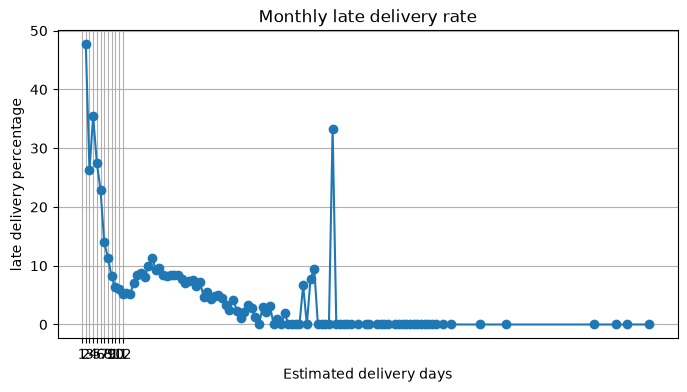

In [69]:
plt.figure(figsize=(8,4))
plt.plot(delivery_analysis.index,delivery_analysis['late_percent'],marker='o')
plt.title('Monthly late delivery rate')
plt.xlabel('Estimated delivery days')
plt.ylabel('late delivery percentage')
plt.xticks(range(1,13))
plt.grid(True)




In [70]:
m_df['estimated_delivery_days'].describe()

count    96470.000000
mean        23.372748
std          8.758421
min          2.000000
25%         18.000000
50%         23.000000
75%         28.000000
max        155.000000
Name: estimated_delivery_days, dtype: float64

In [75]:
m_df['estimated_delivery_days_range'] = pd.cut(m_df['estimated_delivery_days'],
bins=[0,7,14,21,30,100],
labels=['0-7 days', '8-14 days', '15-21 days', '22-30 days', '30+ days']
)

In [79]:
m_df[['estimated_delivery_days_range','estimated_delivery_days']]


,estimated_delivery_days_range,estimated_delivery_days
0,8-14 days,11
1,15-21 days,21
2,15-21 days,15
3,8-14 days,8
4,15-21 days,21
...,...,...
96465,15-21 days,18
96466,22-30 days,27
96467,15-21 days,21
96468,8-14 days,12


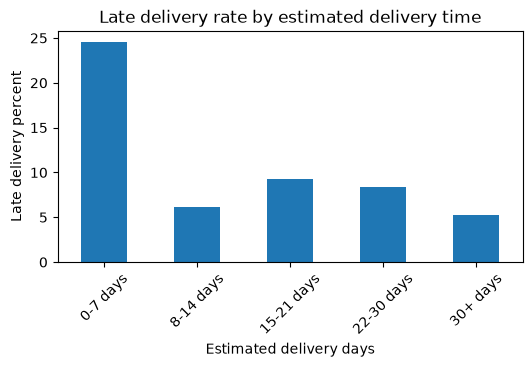

In [84]:
late_rate = m_df.groupby('estimated_delivery_days_range',observed=True)['is_late'].mean()*100
plt.figure(figsize=(6,3))
late_rate.plot(kind='bar')
plt.title('Late delivery rate by estimated delivery time')
plt.xlabel('Estimated delivery days')
plt.ylabel('Late delivery percent')
plt.xticks(rotation=45)
plt.show()

### 2.4 Customer state by late deliveries

In [ ]:
customer_state_late = (m_df.groupby('customer_state')['is_late'].mean()*100).sort_values(ascending=False)
print(customer_state_late.head(15))


customer_state
AL    23.929471
MA    19.665272
PI    15.966387
CE    15.324472
SE    15.223881
BA    14.035627
RJ    13.473684
TO    12.773723
PA    12.367865
ES    12.230576
RR    12.195122
MS    11.554922
PB    11.025145
PE    10.797238
RN    10.759494
Name: is_late, dtype: float64


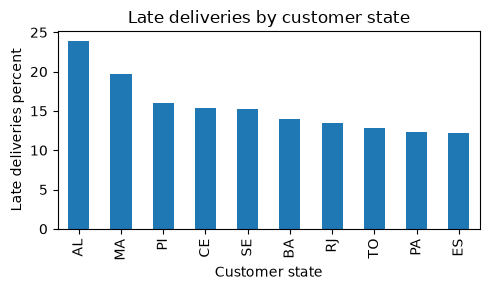

In [98]:
customer_state_late.head(10).plot(kind='bar', figsize=(5,3))
plt.title('Late deliveries by customer state')
plt.xlabel('Customer state')
plt.ylabel('Late deliveries percent')
plt.tight_layout()
plt.show()

### 2.5. Late deliveries by seller state

In [97]:
seller_state_late = (m_df.groupby('seller_state')['is_late'].mean()*100).sort_values(ascending=False)
print(seller_state_late.head(15))

seller_state
AM    66.666667
MA    23.195876
PA    12.500000
RN    10.204082
CE     9.523810
SP     8.794464
MS     8.695652
RJ     8.534816
ES     7.166124
PR     6.602233
PB     6.250000
SC     6.123612
DF     6.000000
BA     5.871560
MG     5.696537
Name: is_late, dtype: float64


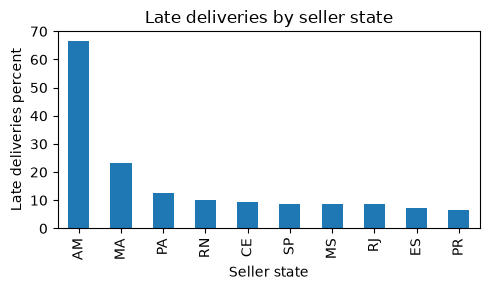

In [99]:
seller_state_late.head(10).plot(kind='bar', figsize=(5,3))
plt.title('Late deliveries by seller state')
plt.xlabel('Seller state')
plt.ylabel('Late deliveries percent')
plt.tight_layout()
plt.show()

#### Recommendation
Investigate seller dispatch times, carrier performance and regional logistics infrastructure in states with higher late delivery rates

### 2.6 Freight cost vs late deliveries

In [103]:
m_df['total_freight_value'] = pd.to_numeric(m_df['total_freight_value'])

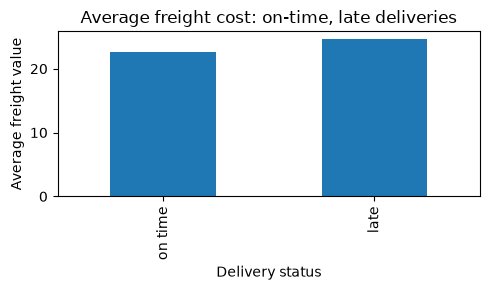

In [111]:
avg_freight_cost = (m_df.groupby('is_late')['total_freight_value']).mean()
avg_freight_cost.index=['on time','late']
avg_freight_cost.plot(kind='bar', figsize=(5,3))
plt.title('Average freight cost: on-time, late deliveries')
plt.xlabel('Delivery status')
plt.ylabel('Average freight value')
plt.tight_layout()
plt.show()

### Key findings
Average freight cost for on time deliveries: 22.63

Average freight cost for late deliveries: 24.63

Difference between the two: 2.0

# Business Insights and Executive Summary
## Project Overview
### Key Business Areas Analyzed
1. Seasonality: Examined monthly delivery patterns to identify potential seasonal variations.
2. Estimated Delivery Time: Evaluated late delivery rates across estimated delivery time ranges.
3. Customer geography: Identified customer states experiencinghigher delivery delays.
4. Seller geography: Estimated seller locations to identify geographical shipping challenges.
5. Freight Cost: Compared average shipping costs between late and on time deliveries.

### Business Recommendations
1. Regional logistics: Investigate delivery performances in states with consistently highlate delivery rates.
2. Seller performance: Monitor dispatch efficiency and cerrier performance across seller regions.
3. Delivery estimates: Review estimated delivery timelines to imrove their reliability.
4. Seasonal planning: Adjust logistics capacity during months associated with increased delivery delays.
5. Freight optimisation: Evaluate shipping expenditure against actual delivery performance.

### Conclusion
The analysis provides insights into geographical, operational and cost related factors associated with late deliveries. These findings can help management prioritize logistics improvements, enhance delivery reliability and improve the overall customer experience.
